# The Curse of Dimensionality

This notebook demonstrates the counter-intuitive phenomena that occur as the number of dimensions ($D$) increases:

1. **Volume Scaling**: How volume grows as $V \sim L^D$.
2. **The Boundary Problem**: Why, in high dimensions, most data points lie near the *boundary* of the feature space.
3. **Sparsity & Scaling**: Using metrics to visualize how data becomes sparse as $D$ increases.

*We restrict our discussion to **2 classes** to keep the boundary surfaces simple and easy to visualize.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import gamma, pi

# For reproducibility
np.random.seed(42)
print('Setup complete')

Setup complete


## 1. Volume Scaling: $V \sim L^D$

The volume of a $D$-dimensional hypercube scales as $V = L^D$. As $D$ increases, the volume grows exponentially.

Furthermore, the volume of an inscribed unit hypersphere shrinks relative to the cube. The volume of a unit hypersphere ($r=1$) is:
$$ V_D = \frac{\pi^{D/2}}{\Gamma(D/2 + 1)} $$
As $D \to \infty$, this ratio $\frac{V_{sphere}}{V_{cube}} \to 0$!

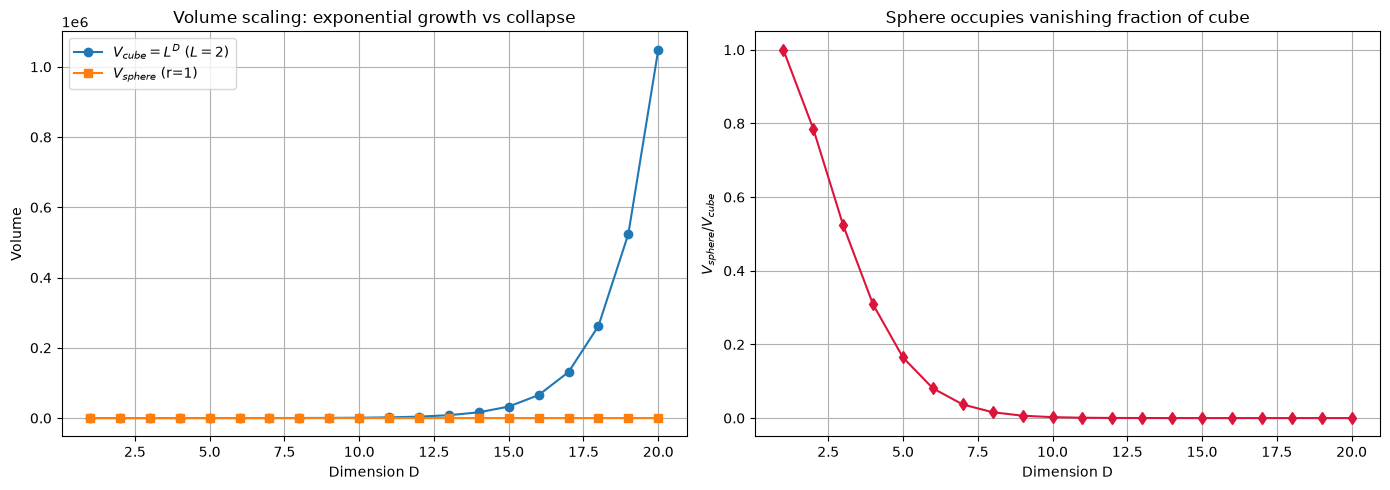

  D |   V_sphere | V_cube (L=2) |    Ratio
  1 |     2.0000 |         2.00 |   1.0000
  2 |     3.1416 |         4.00 |   0.7854
  3 |     4.1888 |         8.00 |   0.5236
  4 |     4.9348 |        16.00 |   0.3084
  5 |     5.2638 |        32.00 |   0.1645
  6 |     5.1677 |        64.00 |   0.0807
  7 |     4.7248 |       128.00 |   0.0369
  8 |     4.0587 |       256.00 |   0.0159
  9 |     3.2985 |       512.00 |   0.0064
 10 |     2.5502 |      1024.00 |   0.0025
 11 |     1.8841 |      2048.00 |   0.0009
 12 |     1.3353 |      4096.00 |   0.0003
 13 |     0.9106 |      8192.00 |   0.0001
 14 |     0.5993 |     16384.00 |   0.0000
 15 |     0.3814 |     32768.00 |   0.0000
 16 |     0.2353 |     65536.00 |   0.0000
 17 |     0.1410 |    131072.00 |   0.0000
 18 |     0.0821 |    262144.00 |   0.0000
 19 |     0.0466 |    524288.00 |   0.0000
 20 |     0.0258 |   1048576.00 |   0.0000


In [2]:
def volume_hypersphere(D):
    return pi**(D/2) / gamma(D/2 + 1)

Ds = np.arange(1, 21)
sphere_vol = [volume_hypersphere(D) for D in Ds]
cube_vol = 2.0**Ds  # cube of side L=2 (r=1 sphere fits exactly inside)
ratios = np.array(sphere_vol) / cube_vol

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(Ds, cube_vol, 'o-', label=r'$V_{cube} = L^D$ ($L=2$)')
ax[0].plot(Ds, sphere_vol, 's-', label=r'$V_{sphere}$ (r=1)')
ax[0].set_xlabel('Dimension D'); ax[0].set_ylabel('Volume')
ax[0].set_title('Volume scaling: exponential growth vs collapse')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(Ds, ratios, 'd-', color='crimson')
ax[1].set_xlabel('Dimension D'); ax[1].set_ylabel(r'$V_{sphere} / V_{cube}$')
ax[1].set_title('Sphere occupies vanishing fraction of cube')
ax[1].grid(True)
plt.tight_layout()
plt.show()

print(f"{'D':>3} | {'V_sphere':>10} | {'V_cube (L=2)':>12} | {'Ratio':>8}")
for D, s, c, r in zip(Ds, sphere_vol, cube_vol, ratios):
    print(f"{D:>3} | {s:>10.4f} | {c:>12.2f} | {r:>8.4f}")

## 2. The Boundary Problem: Data on the Edge

Consider a $D$-dimensional unit cube $[0,1]^D$ containing our training data. If we sample points uniformly, the probability that a point falls in the interior (say, a margin $\epsilon$ away from any boundary) is:

$$ P(\text{interior}) = (1 - 2\epsilon)^D $$

As $D$ increases, $(1 - 2\epsilon)^D \to 0$. Even a tiny margin $\epsilon = 0.01$ excludes almost everything at $D = 100$!

This means **nearly all points lie on (or near) the boundary** of the space.

Probability a point is in the interior (margin eps=0.01):

   D |  P(interior) |  P(on/near boundary)
------------------------------------------
   1 |       0.9800 |               0.0200
   2 |       0.9604 |               0.0396
   3 |       0.9412 |               0.0588
  10 |       0.8171 |               0.1829
  50 |       0.3642 |               0.6358
 100 |       0.1326 |               0.8674


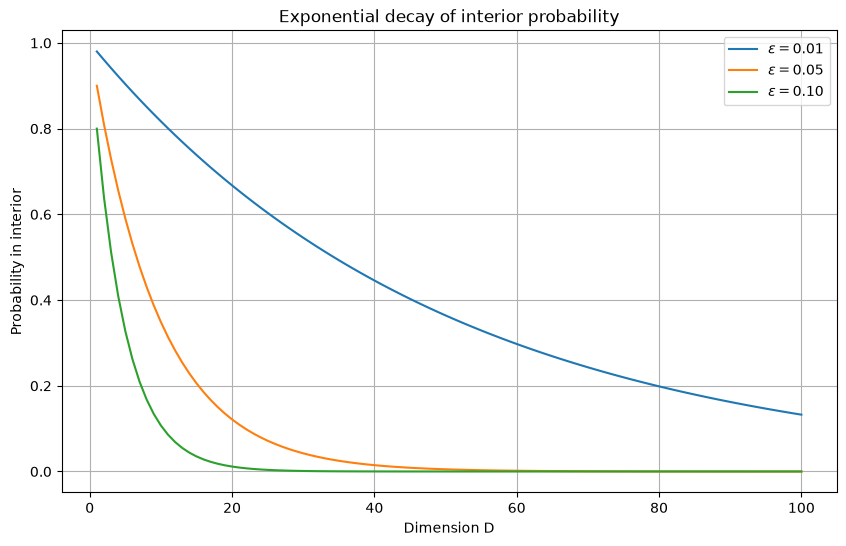

In [3]:
Ds = [1, 2, 3, 10, 50, 100]
eps = 0.01

print(f"Probability a point is in the interior (margin eps={eps}):\n")
print(f"{'D':>4} | {'P(interior)':>12} | {'P(on/near boundary)':>20}")
print('-' * 42)
for D in Ds:
    p_int = (1 - 2*eps)**D
    print(f"{D:>4} | {p_int:>12.4f} | {1 - p_int:>20.4f}")

plt.figure(figsize=(10, 6))
D_range = np.arange(1, 101)
plt.plot(D_range, (1 - 2*0.01)**D_range, label=r'$\epsilon = 0.01$')
plt.plot(D_range, (1 - 2*0.05)**D_range, label=r'$\epsilon = 0.05$')
plt.plot(D_range, (1 - 2*0.1)**D_range, label=r'$\epsilon = 0.10$')
plt.xlabel('Dimension D'); plt.ylabel('Probability in interior')
plt.title('Exponential decay of interior probability')
plt.legend(); plt.grid(True)
plt.show()

## 3. Visualizing 1D, 2D, and 3D

We'll sample points from a unit cube in 1, 2, and 3 dimensions and color-code them by distance to the nearest boundary to see how the boundary effect manifests.

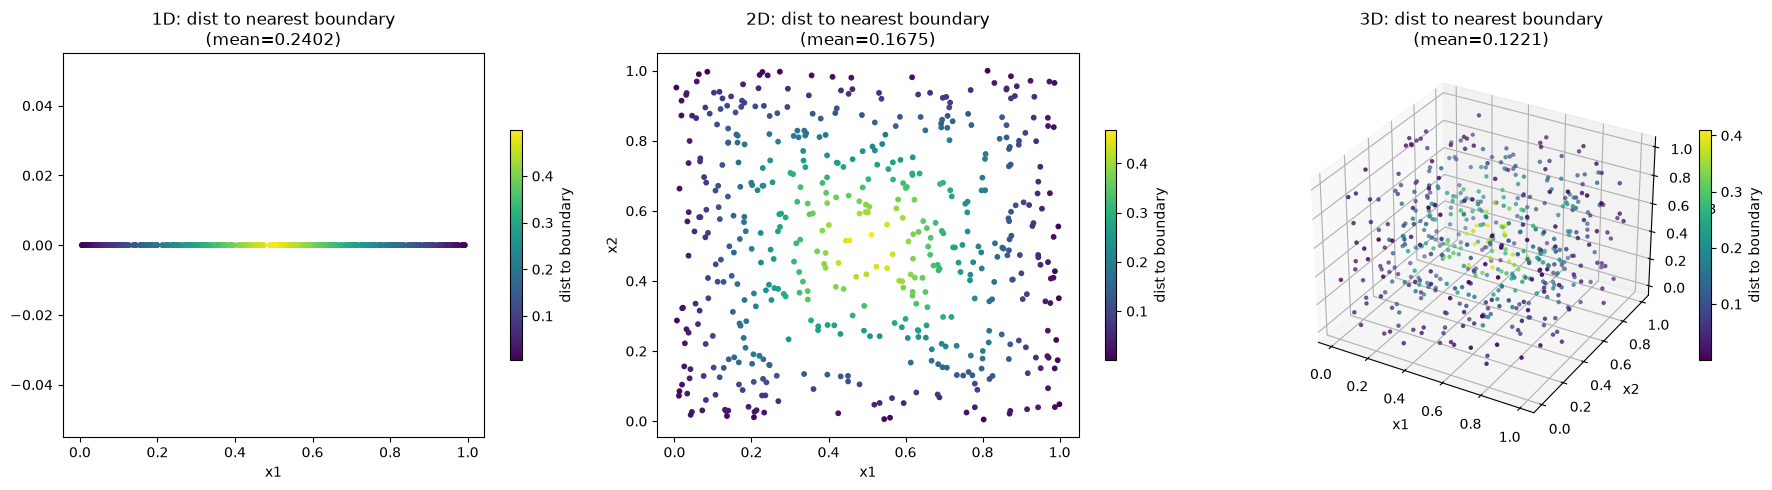

In [4]:
np.random.seed(42)
n = 500

fig = plt.figure(figsize=(18, 5))
for i, D in enumerate([1, 2, 3]):
    pts = np.random.rand(n, D)
    # distance to nearest boundary (min distance to any face)
    dist_to_boundary = np.minimum(pts, 1 - pts).min(axis=1)
    
    ax = fig.add_subplot(1, 3, i+1, projection='3d' if D == 3 else None)
    if D == 1:
        sc = ax.scatter(pts[:, 0], np.zeros_like(pts[:, 0]), c=dist_to_boundary, cmap='viridis', s=10)
        ax.set_xlabel('x1')
    elif D == 2:
        sc = ax.scatter(pts[:, 0], pts[:, 1], c=dist_to_boundary, cmap='viridis', s=10)
        ax.set_xlabel('x1'); ax.set_ylabel('x2')
    else:
        sc = ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=dist_to_boundary, cmap='viridis', s=5)
        ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_zlabel('x3')
    ax.set_title(f'{D}D: dist to nearest boundary\n(mean={dist_to_boundary.mean():.4f})')
    plt.colorbar(sc, ax=ax, shrink=0.6, label='dist to boundary')
plt.tight_layout()
plt.show()

## 4. Scaling Metrics: Sparsity & Distance Concentration

In high dimensions, the ratio of nearest-neighbor distance to farthest-neighbor distance approaches 1 — distances become uniform, making distance-based methods (kNN, clustering) unreliable. This is **distance concentration**.

We also demonstrate sparsity: fixed sample size $N$, the space grows as $L^D$, so density $\propto N / L^D \to 0$.

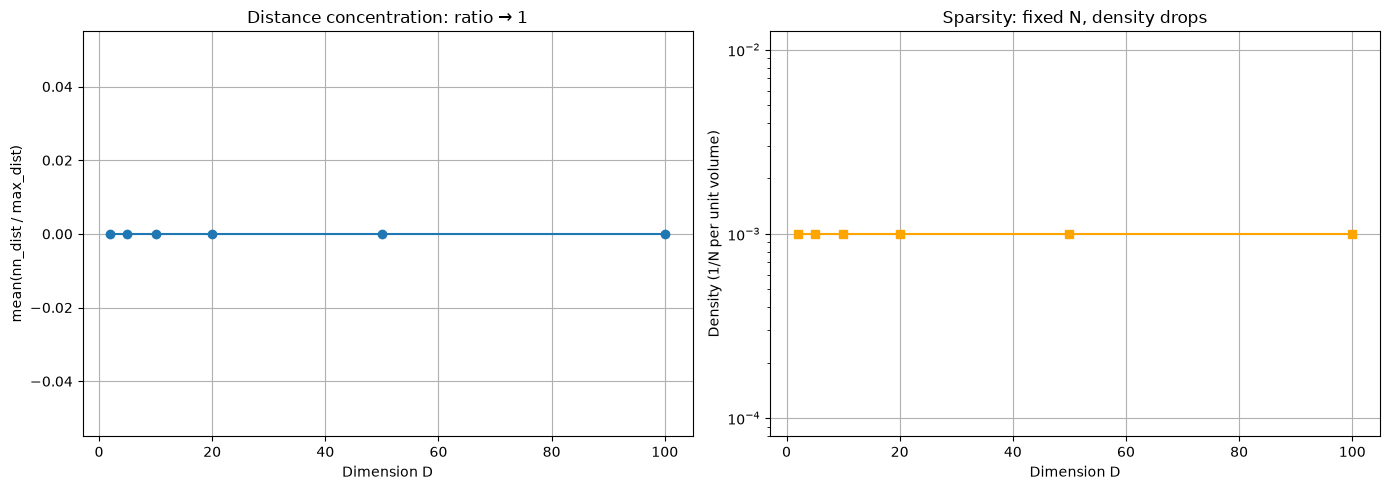

   D |  mean nn/max ratio
   2 |             0.0000
   5 |             0.0000
  10 |             0.0000
  20 |             0.0000
  50 |             0.0000
 100 |             0.0000


In [5]:
np.random.seed(0)
N = 1000
D_range = [2, 5, 10, 20, 50, 100]

nn_ratios = []
densities = []
for D in D_range:
    pts = np.random.rand(N, D)
    # pairwise distances (subsample to keep it fast for large D)
    if N > 200:
        idx = np.random.choice(N, 200, replace=False)
        sub = pts[idx]
    else:
        sub = pts
    diff = sub[:, None, :] - sub[None, :, :]
    dists = np.sqrt((diff**2).sum(-1))
    np.fill_diagonal(dists, np.inf)
    nn = dists.min(axis=1)
    far = dists.max(axis=1)
    nn_ratios.append(np.mean(nn / far))
    densities.append(N / (1.0**D))  # unit volume = 1

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(D_range, nn_ratios, 'o-')
ax[0].set_xlabel('Dimension D'); ax[0].set_ylabel('mean(nn_dist / max_dist)')
ax[0].set_title('Distance concentration: ratio → 1')
ax[0].grid(True)

ax[1].semilogy(D_range, [1.0 / N for _ in D_range], 's-', color='orange')
ax[1].set_xlabel('Dimension D'); ax[1].set_ylabel('Density (1/N per unit volume)')
ax[1].set_title('Sparsity: fixed N, density drops')
ax[1].grid(True)
plt.tight_layout()
plt.show()

print(f"{'D':>4} | {'mean nn/max ratio':>18}")
for D, r in zip(D_range, nn_ratios):
    print(f"{D:>4} | {r:>18.4f}")

## Takeaways

- **Volume explodes** as $L^D$, but interesting regions (spheres, interiors) become vanishingly small.
- **Data lives on the boundary**: $P(\text{interior}) = (1-2\epsilon)^D \to 0$.
- **Distances concentrate**: neighbors and outliers become indistinguishable.
- **Fixed $N$ is hopeless**: density $\propto N/L^D$ collapses. You need exponentially more data per dimension added.